# Major Project – Cardiovascular Disease Prediction

**Models:** SVM, Random Forest, Logistic Regression  
**Train/Test:** 80:20  
**Tuning:** RandomizedSearchCV  
**Dataset:** `CVD_cleaned.csv`



In [8]:
# 1. Imports and dataset loading
import io
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

DATA_PATH = "/content/CVD_cleaned.csv"

try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
    df = pd.read_csv(io.BytesIO(uploaded[csv_name]))

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (308854, 19)


,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150,32.66,14.54,Yes,0,30,16,12
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165,77.11,28.29,No,0,30,0,4
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163,88.45,33.47,No,4,12,3,16
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180,93.44,28.73,No,0,30,30,8
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191,88.45,24.37,Yes,0,8,4,0


## 2. Dataset inspection

In [9]:
print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nTarget distribution:")
display(df["Heart_Disease"].value_counts())


Columns:
['General_Health', 'Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Height_(cm)', 'Weight_(kg)', 'BMI', 'Smoking_History', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']

Missing values:


,Missing Values
General_Health,0
Checkup,0
Exercise,0
Heart_Disease,0
Skin_Cancer,0
Other_Cancer,0
Depression,0
Diabetes,0
Arthritis,0
Sex,0



Target distribution:


,count
Heart_Disease,
No,283883
Yes,24971


## 3. Separate features and target

In [10]:
TARGET = "Heart_Disease"

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Features:", X.shape)
print("Target:", y.shape)
print("Classes:", y.unique())


Features: (308854, 18)
Target: (308854,)
Classes: ['No' 'Yes']


## 4. 80:20 train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training data: {X_train.shape[0]} rows")
print(f"Testing data : {X_test.shape[0]} rows")


Training data: 247083 rows
Testing data : 61771 rows


## 5. Preprocessing

In [12]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical columns:", numeric_features)
print("Categorical columns:", categorical_features)


Numerical columns: ['Height_(cm)', 'Weight_(kg)', 'BMI', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']
Categorical columns: ['General_Health', 'Checkup', 'Exercise', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Smoking_History']


## 6. Build SVM, Random Forest and Logistic Regression models

In [13]:
models = {
    "SVM": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearSVC(C=1.0, random_state=42, max_iter=3000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=80,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            C=1.0,
            max_iter=500,
            solver="liblinear",
            class_weight="balanced",
            random_state=42
        ))
    ])
}


## 7. Train and test all three models

Training SVM...
SVM Accuracy: 0.9192 (91.92%)

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.57      0.00      0.01      4994

    accuracy                           0.92     61771
   macro avg       0.74      0.50      0.48     61771
weighted avg       0.89      0.92      0.88     61771



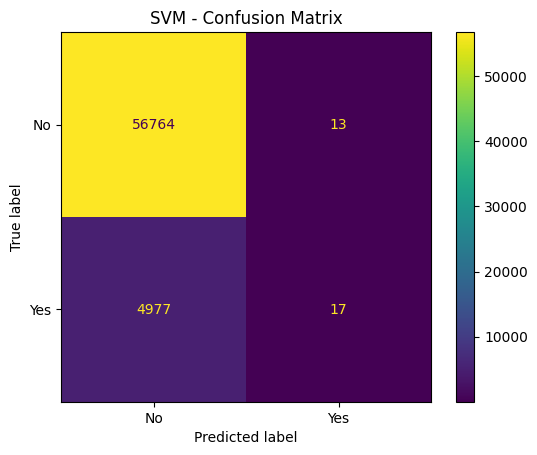

Training Random Forest...
Random Forest Accuracy: 0.9183 (91.83%)

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.45      0.05      0.08      4994

    accuracy                           0.92     61771
   macro avg       0.69      0.52      0.52     61771
weighted avg       0.88      0.92      0.89     61771



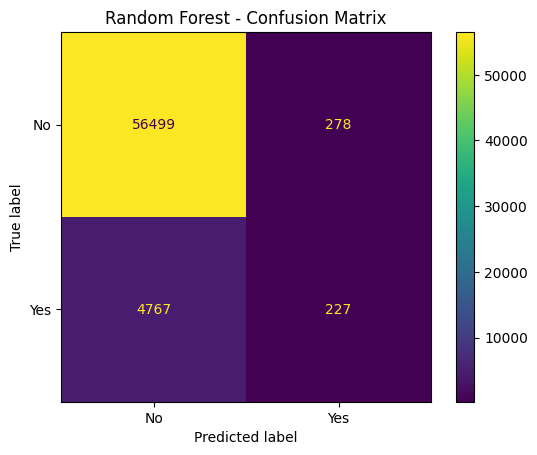

Training Logistic Regression...
Logistic Regression Accuracy: 0.7383 (73.83%)

Classification Report:
              precision    recall  f1-score   support

          No       0.98      0.73      0.84     56777
         Yes       0.21      0.80      0.33      4994

    accuracy                           0.74     61771
   macro avg       0.59      0.77      0.58     61771
weighted avg       0.91      0.74      0.80     61771



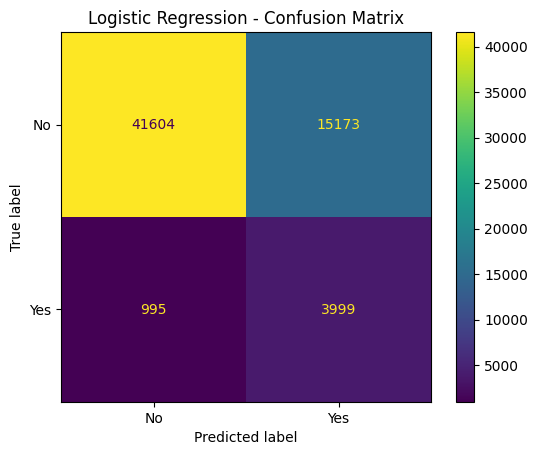

In [14]:
results = {}
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    results[name] = {
        "accuracy": accuracy,
        "predictions": y_pred
    }

    print(f"{name} Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(values_format="d")

    plt.title(f"{name} - Confusion Matrix")
    plt.show()


## 8. Accuracy comparison

,Model,Accuracy
0,SVM,0.919218
1,Random Forest,0.918327
2,Logistic Regression,0.738259


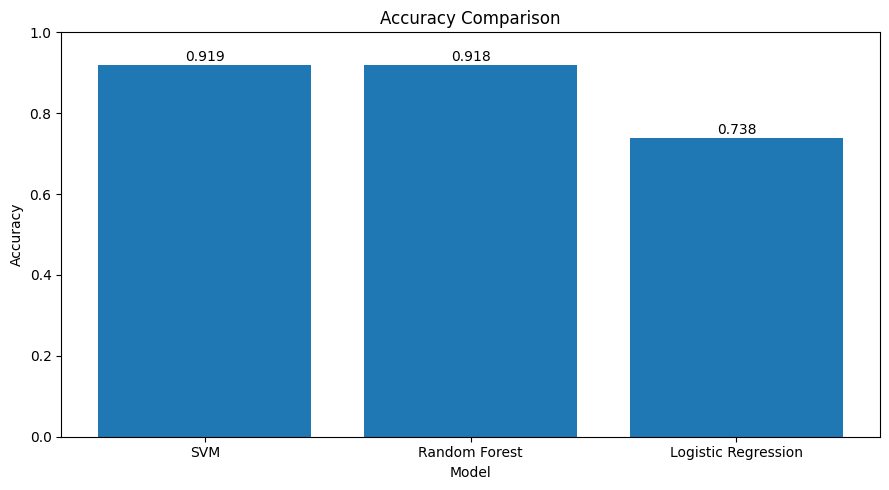

In [15]:
accuracy_df = pd.DataFrame({
    "Model": list(results.keys()),
    "Accuracy": [results[m]["accuracy"] for m in results]
})

display(accuracy_df)

plt.figure(figsize=(9,5))
bars = plt.bar(accuracy_df["Model"], accuracy_df["Accuracy"])
plt.ylim(0, 1)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")

for bar, value in zip(bars, accuracy_df["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 9. Randomized hyperparameter search

To keep Colab fast, randomized search is performed on a **15,000-row stratified subset** of the training data.

Only **3 random parameter combinations** are tested per model with **2-fold cross-validation**.  
After finding the best parameters, the selected model is retrained on the complete training set.


In [16]:
# Fast tuning subset
TUNE_SIZE = min(15000, len(X_train))

X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=TUNE_SIZE,
    random_state=42,
    stratify=y_train
)

print("Tuning subset:", X_tune.shape)

search_spaces = {
    "SVM": (
        models["SVM"],
        {
            "model__C": [0.01, 0.1, 1, 3, 10]
        }
    ),

    "Random Forest": (
        models["Random Forest"],
        {
            "model__n_estimators": [50, 80, 120],
            "model__max_depth": [10, 20, None],
            "model__min_samples_split": [2, 5, 10],
            "model__max_features": ["sqrt", "log2"]
        }
    ),

    "Logistic Regression": (
        models["Logistic Regression"],
        {
            "model__C": [0.01, 0.1, 1, 3, 10]
        }
    )
}

best_params = {}
tuned_models = {}

for name, (base_model, params) in search_spaces.items():

    print("\n" + "="*60)
    print("Tuning:", name)
    print("="*60)

    search = RandomizedSearchCV(
        estimator=base_model,
        param_distributions=params,
        n_iter=3,
        scoring="accuracy",
        cv=2,
        random_state=42,
        n_jobs=-1,
        verbose=0
    )

    search.fit(X_tune, y_tune)

    best_params[name] = search.best_params_

    print("Best parameters:", search.best_params_)
    print("Best CV accuracy:", round(search.best_score_, 4))

    # Train selected configuration on full training set
    final_model = base_model.set_params(**search.best_params_)
    final_model.fit(X_train, y_train)
    tuned_models[name] = final_model

print("\nFAST RANDOMIZED SEARCH COMPLETED.")


Tuning subset: (15000, 18)

Tuning: SVM
Best parameters: {'model__C': 0.1}
Best CV accuracy: 0.9191

Tuning: Random Forest
Best parameters: {'model__n_estimators': 80, 'model__min_samples_split': 2, 'model__max_features': 'sqrt', 'model__max_depth': 20}
Best CV accuracy: 0.9187

Tuning: Logistic Regression
Best parameters: {'model__C': 0.1}
Best CV accuracy: 0.7517

FAST RANDOMIZED SEARCH COMPLETED.


## 10. Evaluate tuned models on unseen test data

TUNED MODEL: SVM
Accuracy: 0.9192 (91.92%)

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.57      0.00      0.01      4994

    accuracy                           0.92     61771
   macro avg       0.74      0.50      0.48     61771
weighted avg       0.89      0.92      0.88     61771



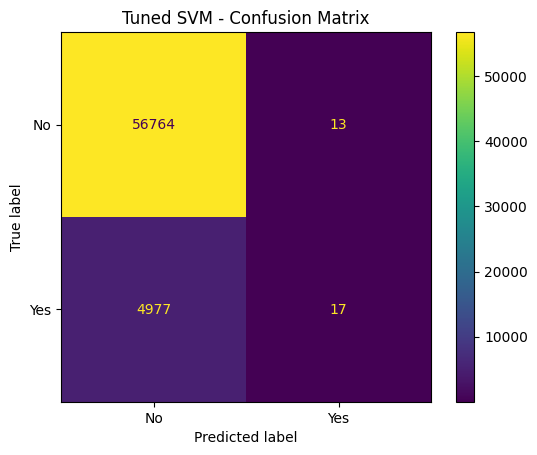

TUNED MODEL: Random Forest
Accuracy: 0.8637 (86.37%)

Classification Report:
              precision    recall  f1-score   support

          No       0.95      0.90      0.92     56777
         Yes       0.27      0.42      0.33      4994

    accuracy                           0.86     61771
   macro avg       0.61      0.66      0.63     61771
weighted avg       0.89      0.86      0.88     61771



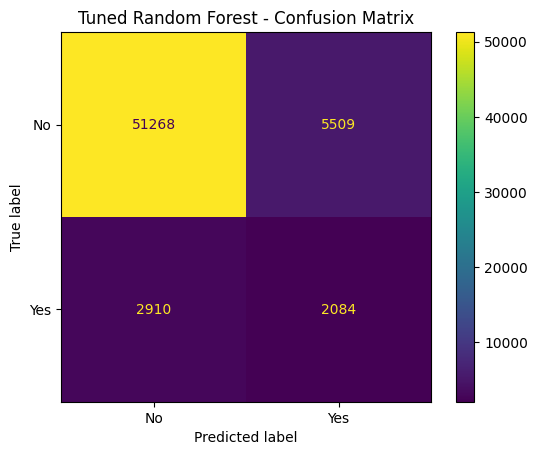

TUNED MODEL: Logistic Regression
Accuracy: 0.7385 (73.85%)

Classification Report:
              precision    recall  f1-score   support

          No       0.98      0.73      0.84     56777
         Yes       0.21      0.80      0.33      4994

    accuracy                           0.74     61771
   macro avg       0.59      0.77      0.58     61771
weighted avg       0.91      0.74      0.80     61771



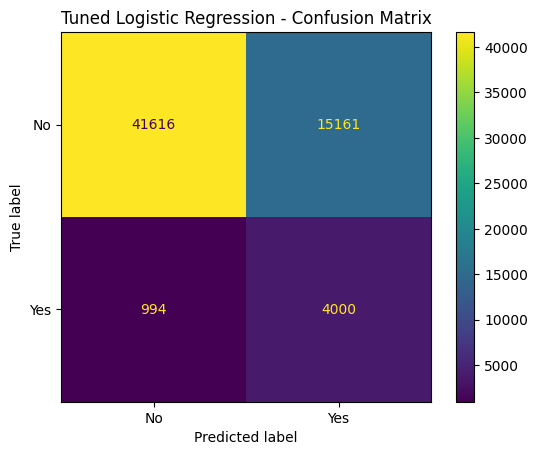

In [17]:
tuned_results = {}

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    tuned_results[name] = {
        "accuracy": accuracy,
        "predictions": y_pred
    }

    print("="*80)
    print("TUNED MODEL:", name)
    print("="*80)
    print(f"Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(values_format="d")

    plt.title(f"Tuned {name} - Confusion Matrix")
    plt.show()


## 11. Tuned model accuracy comparison

,Model,Tuned Accuracy
0,SVM,0.919218
1,Random Forest,0.863706
2,Logistic Regression,0.738470


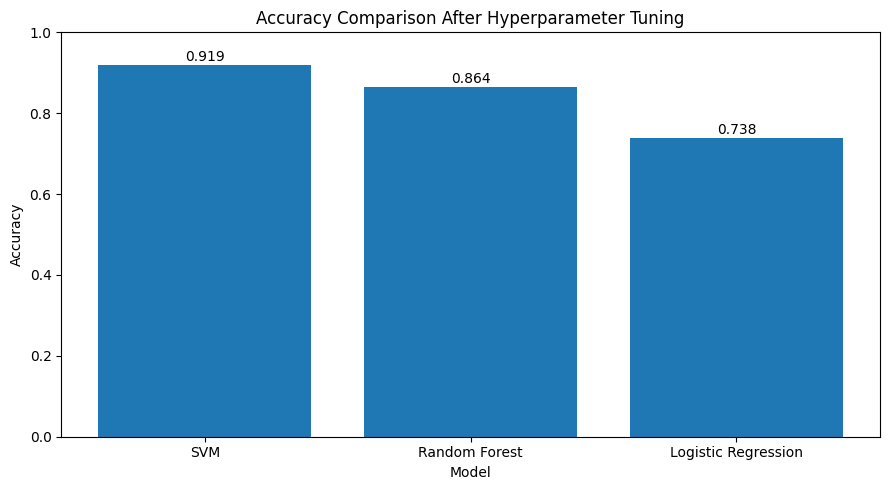

In [18]:
tuned_accuracy_df = pd.DataFrame({
    "Model": list(tuned_results.keys()),
    "Tuned Accuracy": [tuned_results[m]["accuracy"] for m in tuned_results]
})

display(tuned_accuracy_df)

plt.figure(figsize=(9,5))
bars = plt.bar(
    tuned_accuracy_df["Model"],
    tuned_accuracy_df["Tuned Accuracy"]
)

plt.ylim(0,1)
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison After Hyperparameter Tuning")

for bar, value in zip(bars, tuned_accuracy_df["Tuned Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 12. AI-style prediction for a single input

A single record from the test dataset is passed to the tuned models. This demonstrates how the trained models can be used to predict the health-status class for one person.


In [19]:
# Select one individual record from unseen test data
single_input = X_test.iloc[[0]].copy()
actual_status = y_test.iloc[0]

print("Single input:")
display(single_input)

print("Actual dataset status:", actual_status)

print("\nPredictions:")
for name, model in tuned_models.items():
    prediction = model.predict(single_input)[0]
    print(f"{name}: {prediction}")

# Final AI-style demonstration using tuned Random Forest
final_model = tuned_models["Random Forest"]
final_prediction = final_model.predict(single_input)[0]

print("\n" + "="*60)
print("AI HEALTH STATUS PREDICTION")
print("="*60)
print("Predicted Heart Disease Status:", final_prediction)
print("Actual Dataset Status:", actual_status)
print("="*60)

print("\nNote: This is an academic ML prediction and is NOT a medical diagnosis.")


Single input:


,General_Health,Checkup,Exercise,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
36889,Good,Within the past year,Yes,No,No,No,No,No,Female,50-54,170,63.5,21.93,Yes,30,12,4,30


Actual dataset status: No

Predictions:
SVM: No
Random Forest: No
Logistic Regression: No

AI HEALTH STATUS PREDICTION
Predicted Heart Disease Status: No
Actual Dataset Status: No

Note: This is an academic ML prediction and is NOT a medical diagnosis.


# Conclusion

The project successfully implemented:

1. 80:20 train-test split
2. SVM model
3. Random Forest model
4. Logistic Regression model
5. Accuracy, classification report and confusion matrix
6. Accuracy comparison bar chart
7. Randomized hyperparameter search
8. Evaluation of tuned models on unseen data
9. Single-record AI-style health-status prediction


